In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

housing = fetch_california_housing(as_frame=True)
df = housing.frame.copy()

X = df.drop(columns="MedHouseVal")
y = df["MedHouseVal"]

print("Dataset shape:", df.shape)
print("Missing values:", df.isnull().sum().sum())
display(df.head())

Dataset shape: (20640, 9)
Missing values: 0


,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


,count,mean,std,min,25%,50%,75%,max
MedInc,20640.0,3.870671,1.899822,0.499900,2.563400,3.534800,4.743250,15.000100
HouseAge,20640.0,28.639486,12.585558,1.000000,18.000000,29.000000,37.000000,52.000000
AveRooms,20640.0,5.429000,2.474173,0.846154,4.440716,5.229129,6.052381,141.909091
AveBedrms,20640.0,1.096675,0.473911,0.333333,1.006079,1.048780,1.099526,34.066667
Population,20640.0,1425.476744,1132.462122,3.000000,787.000000,1166.000000,1725.000000,35682.000000
AveOccup,20640.0,3.070655,10.386050,0.692308,2.429741,2.818116,3.282261,1243.333333
Latitude,20640.0,35.631861,2.135952,32.540000,33.930000,34.260000,37.710000,41.950000
Longitude,20640.0,-119.569704,2.003532,-124.350000,-121.800000,-118.490000,-118.010000,-114.310000
MedHouseVal,20640.0,2.068558,1.153956,0.149990,1.196000,1.797000,2.647250,5.000010


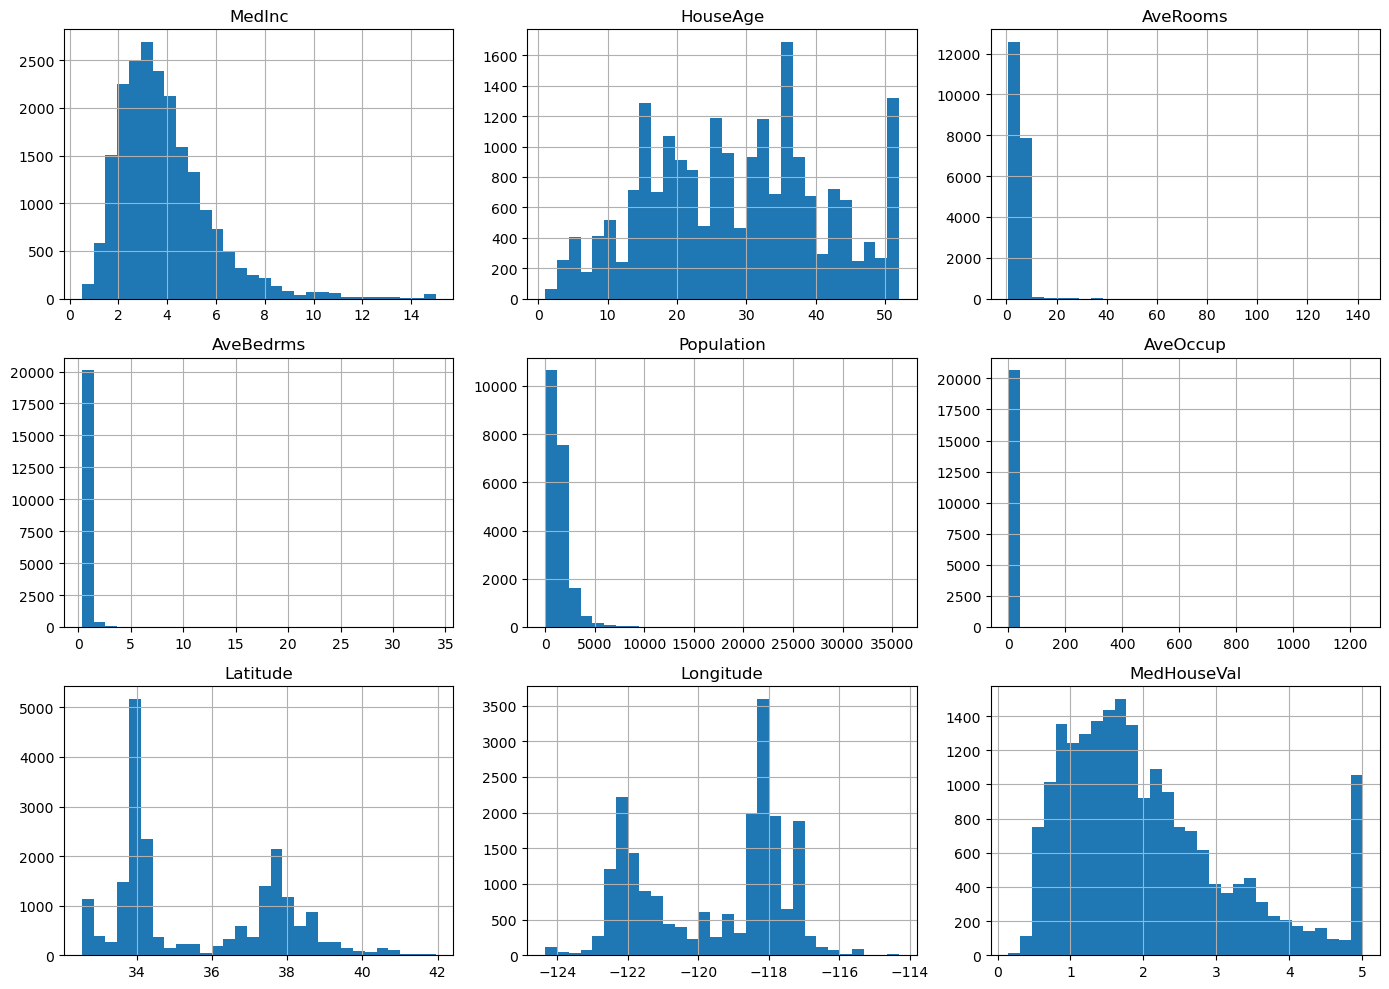

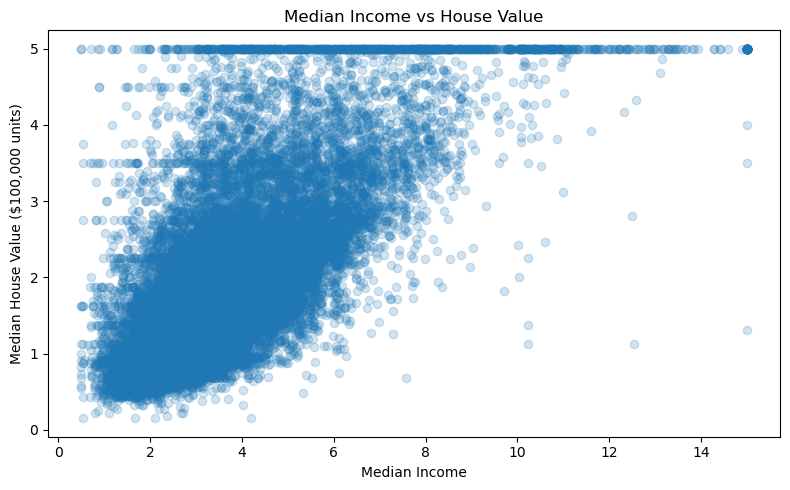

In [2]:
display(df.describe().T)

df.hist(figsize=(14, 10), bins=30)
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
plt.scatter(df["MedInc"], y, alpha=0.2)
plt.xlabel("Median Income")
plt.ylabel("Median House Value ($100,000 units)")
plt.title("Median Income vs House Value")
plt.tight_layout()
plt.show()

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42
)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

Training samples: 16512
Testing samples: 4128


In [4]:
models = {
    "Linear Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", LinearRegression())
    ]),

    "Ridge Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", Ridge())
    ]),

    "Lasso Regression": Pipeline([
        ("scaler", StandardScaler()),
        ("model", Lasso(max_iter=10000))
    ])
}

param_grids = {
    "Linear Regression": {},

    "Ridge Regression": {
        "model__alpha": [0.01, 0.1, 1, 10, 100]
    },

    "Lasso Regression": {
        "model__alpha": [0.001, 0.01, 0.1, 1, 10]
    }
}

results = []
fitted_models = {}

for name, pipeline in models.items():
    search = GridSearchCV(
        estimator=pipeline,
        param_grid=param_grids[name],
        scoring="neg_mean_squared_error",
        cv=5,
        n_jobs=-1
    )

    search.fit(X_train, y_train)
    fitted_models[name] = search.best_estimator_

    predictions = search.predict(X_test)

    results.append({
        "Model": name,
        "Best Parameters": search.best_params_,
        "CV RMSE": np.sqrt(-search.best_score_),
        "Test MAE": mean_absolute_error(y_test, predictions),
        "Test RMSE": np.sqrt(mean_squared_error(y_test, predictions)),
        "Test R2": r2_score(y_test, predictions)
    })

regression_results = pd.DataFrame(results)
display(
    regression_results.sort_values("Test RMSE")
    .reset_index(drop=True)
)

,Model,Best Parameters,CV RMSE,Test MAE,Test RMSE,Test R2
0,Lasso Regression,{'model__alpha': 0.001},0.720598,0.533145,0.744642,0.576856
1,Ridge Regression,{'model__alpha': 0.01},0.720601,0.533200,0.745581,0.575788
2,Linear Regression,{},0.720601,0.533200,0.745581,0.575788


Best model by test RMSE: Lasso Regression
Test MAE: 0.5331447750392391
Test RMSE: 0.7446417662764214
Test R2: 0.5768562568705682


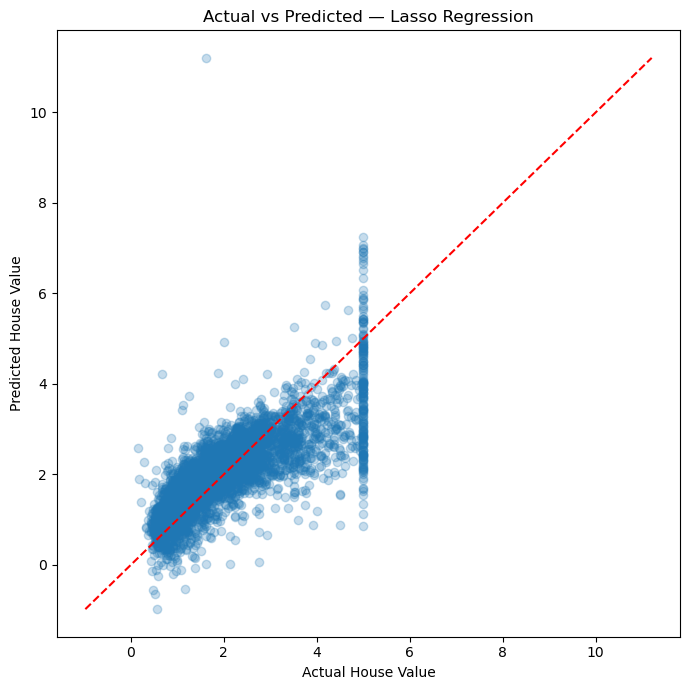

In [5]:
best_name = (
    regression_results
    .sort_values("Test RMSE")
    .iloc[0]["Model"]
)

best_model = fitted_models[best_name]
predictions = best_model.predict(X_test)

print("Best model by test RMSE:", best_name)
print("Test MAE:", mean_absolute_error(y_test, predictions))
print("Test RMSE:", np.sqrt(mean_squared_error(y_test, predictions)))
print("Test R2:", r2_score(y_test, predictions))

plt.figure(figsize=(7, 7))
plt.scatter(y_test, predictions, alpha=0.25)

limits = [
    min(y_test.min(), predictions.min()),
    max(y_test.max(), predictions.max())
]

plt.plot(limits, limits, "r--")
plt.xlabel("Actual House Value")
plt.ylabel("Predicted House Value")
plt.title(f"Actual vs Predicted — {best_name}")
plt.tight_layout()
plt.show()